# Waite Chromatin Atlas
**Robert Waite · M.S. candidate in Biotechnology · University of South Florida (USF)**

## Overview

This notebook compares published ENCODE/Broad ChromHMM annotations in GM12878
and K562 to ask whether strong-enhancer annotations are less shared than active
promoters on hg19 chromosome 22. Exact interval arithmetic produces coverage,
class overlap, sensitivity comparisons and a paired-state map.

The main result is a strong-enhancer Jaccard of **0.0732**, compared with
**0.4740** for active promoters, across 31,467,632 eligible bases.

## Run this notebook

Use Python 3.12 with the dependencies in `requirements-dev.txt`. Open the notebook
from the repository root and run all cells. Source data are included; a missing
source file can be downloaded with checksum verification. No GPU is required.

## Biological observation unit

The source observations are genomic intervals with model-derived state labels,
inferred from combinations of histone ChIP-seq signals. These labels describe
candidate functional elements; they do not directly demonstrate enhancer
function. The two cell lines are not a time course. The comparison unit is an
atomic interval with both labels; aggregation is weighted by its number of bases.


In [1]:
from pathlib import Path
import sys
import importlib.metadata

ROOT = Path.cwd()
if not (ROOT / "config.json").is_file():
    raise FileNotFoundError("Open this notebook from the repository root.")
sys.path.insert(0, str(ROOT))
required = {"matplotlib": "3.10.7", "numpy": "2.5.4"}
for package, version in required.items():
    if importlib.metadata.version(package) != version:
        raise RuntimeError("Install requirements-dev.txt before running this notebook.")
print("Python:", sys.version.split()[0])
print("Analysis dependencies:", {p: importlib.metadata.version(p) for p in required})


Python: 3.12.14
Analysis dependencies: {'matplotlib': '3.10.7', 'numpy': '2.5.4'}


## 1. Verify sources and build exact comparable intervals

The immutable source hashes are checked first. The source files use hg19
coordinates lifted from hg18. BED `[start, end)` is zero-based and half-open;
length is `end - start`. We never round lifted intervals to 200 bp. The primary
universe is covered territory common to both lines, excluding any base labeled
14/15 in either line. State 13 is retained. Missing coverage is not zero activity.


In [2]:
from chromatin_atlas.pipeline import run
result = run(ROOT, ROOT / "config.json", ROOT, download=True)


{
  "eligible_bp": 31467632,
  "overlap": {
    "active_promoter": {
      "gm_only_bp": 193800,
      "shared_bp": 265800,
      "k_only_bp": 101200,
      "union_bp": 560800,
      "gm_bp": 459600,
      "k_bp": 367000,
      "jaccard": 0.4739657631954351,
      "gm_retained": 0.5783289817232375,
      "k_retained": 0.7242506811989101
    },
    "strong_enhancer": {
      "gm_only_bp": 955200,
      "shared_bp": 123400,
      "k_only_bp": 607202,
      "union_bp": 1685802,
      "gm_bp": 1078600,
      "k_bp": 730602,
      "jaccard": 0.07319958097095626,
      "gm_retained": 0.11440756536250696,
      "k_retained": 0.1689018097404606
    },
    "broad_enhancer": {
      "gm_only_bp": 1957200,
      "shared_bp": 622402,
      "k_only_bp": 1769454,
      "union_bp": 4349056,
      "gm_bp": 2579602,
      "k_bp": 2391856,
      "jaccard": 0.14311197648409218,
      "gm_retained": 0.24127830572313094,
      "k_retained": 0.26021717026443064
    }
  }
}


In [3]:
from IPython.display import display, Markdown, Image
qc = result["qc"]
rows = ["| Cell | Whole-file rows | chr22 rows | Covered bp | Internal gap bp | Duplicates |",
        "|---|---:|---:|---:|---:|---:|"]
for cell, q in qc.items():
    rows.append(f"| {cell} | {q['whole_file_rows']:,} | {q['selected_rows']:,} | {q['selected_bp']:,} | {q['internal_gap_bp']:,} | {q['duplicate_selected_rows']} |")
display(Markdown("\n".join(rows)))
primary = result["scenarios"]["primary"]
print("Common-covered bp:", f"{result['common_covered_bp']:,}")
print("Primary eligible bp:", f"{primary['eligible_bp']:,}")
print("Excluded repetitive/CNV bp:", f"{primary['excluded_bp']:,}")
print("Common atomic intervals:", result["common_atom_count"])
assert primary['eligible_bp'] + primary['excluded_bp'] == result['common_covered_bp']


| Cell | Whole-file rows | chr22 rows | Covered bp | Internal gap bp | Duplicates |
|---|---:|---:|---:|---:|---:|
| GM12878 | 571,339 | 11,497 | 34,852,028 | 342,506 | 0 |
| K562 | 622,257 | 12,846 | 34,852,028 | 342,506 | 0 |

Common-covered bp: 34,852,028
Primary eligible bp: 31,467,632
Excluded repetitive/CNV bp: 3,384,396
Common atomic intervals: 21870


## 2. Base-pair composition

Every state coverage numerator uses the **same eligible-territory denominator**.
BED row counts cannot substitute for coverage because interval lengths vary.
The marginal coverages must each sum to the eligible territory.


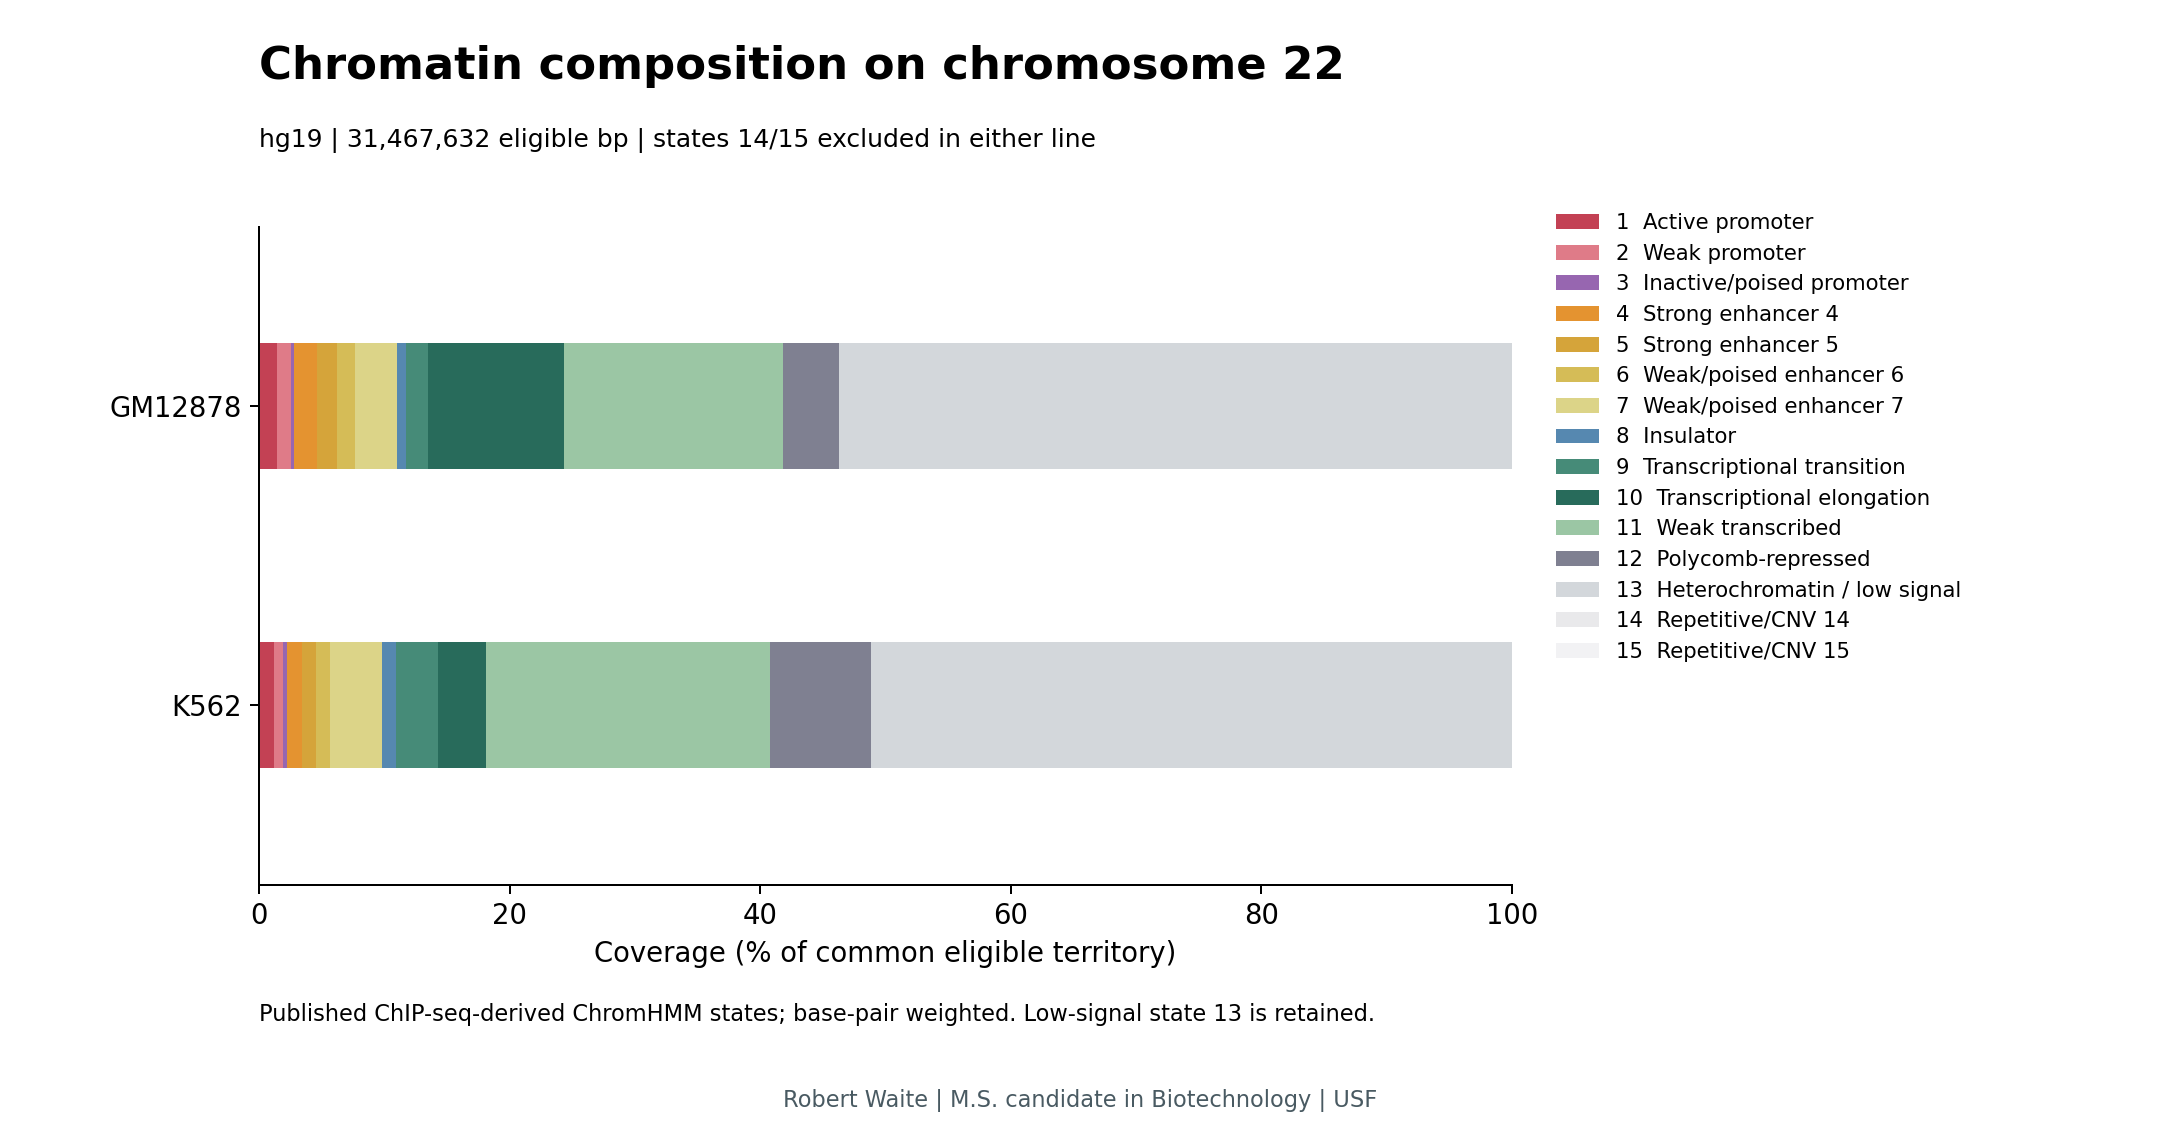

In [4]:
assert sum(r["gm_bp"] for r in primary["coverage"]) == primary["eligible_bp"]
assert sum(r["k_bp"] for r in primary["coverage"]) == primary["eligible_bp"]
display(Image(filename=str(ROOT / "figures/01_state_coverage.png")))


**Figure 1.** Base-pair coverage of published histone-ChIP-seq-derived
ChromHMM states in the two lines on common eligible hg19 chr22 territory. Each
bar totals 100% of 31,467,632 bp. State 13 is included; states 14/15 in either
line are excluded. This is annotation composition, not a quantitative assay of
enhancer strength. Original chart: Robert Waite.

## 3. Exact class overlap

For class C, let A and B be its covered bases in GM12878 and K562 after the same
territory mask. `J(C) = |A ∩ B| / |A ∪ B|`. The union partitions into
GM12878-only, shared, and K562-only bases. Each class therefore has its own
denominator. Directional retention is shared divided by that line's class bases.
An empty class union gives an undefined Jaccard, not zero.

Hand-check without a territory restriction: A=[100,200), B=[150,250) have 50
shared bp, 150 union bp and J=1/3. Restricting both to their common coverage would
instead leave only [150,200), for J=1. This distinction explains why we report
the coverage universe explicitly. In the supplied real files the two chr22
coverage footprints coincide.


Active promoter: 265,800 shared / 560,800 union bp = J 0.473966
Strong enhancer: 123,400 shared / 1,685,802 union bp = J 0.073200
Promoter-minus-enhancer gap: 40.08 percentage points


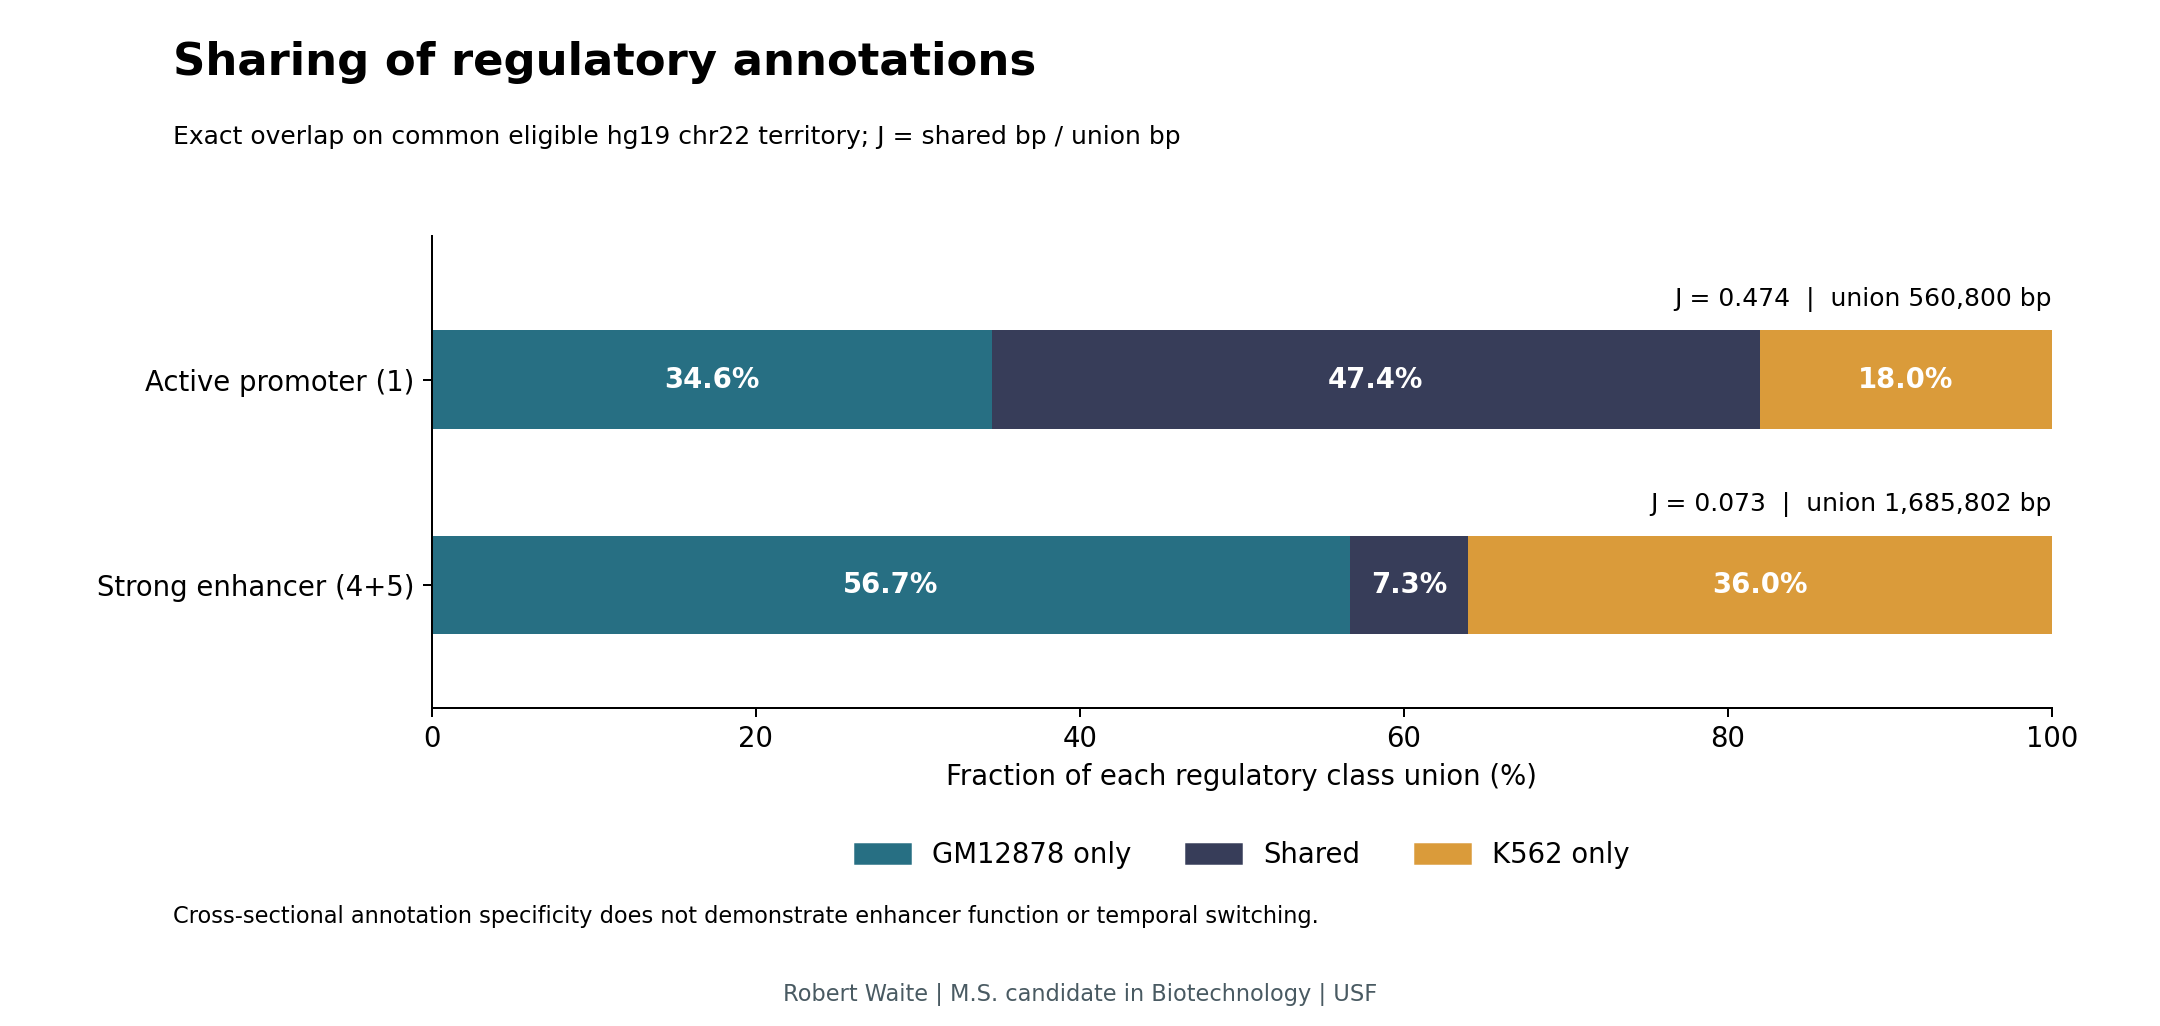

In [5]:
p = primary["overlap"]["active_promoter"]
e = primary["overlap"]["strong_enhancer"]
for name, r in [("Active promoter", p), ("Strong enhancer", e)]:
    assert r["union_bp"] == r["gm_only_bp"] + r["shared_bp"] + r["k_only_bp"]
    print(f"{name}: {r['shared_bp']:,} shared / {r['union_bp']:,} union bp = J {r['jaccard']:.6f}")
print(f"Promoter-minus-enhancer gap: {(p['jaccard']-e['jaccard'])*100:.2f} percentage points")
display(Image(filename=str(ROOT / "figures/02_regulatory_sharing.png")))


**Figure 2.** Class-union-normalized overlap of active-promoter (state 1)
and strong-enhancer (states 4/5) annotations. Strong-enhancer Jaccard is 0.073200;
active-promoter Jaccard is 0.473966. “Only” means only in that annotation class in
the chosen pair of lines. It does not establish lack of function in the other
line. Adjacent bases and intervals are not independent biological replicates;
we do not calculate a base-count-based p-value.

## 4. Sensitivity to mask and enhancer definition

Repeat the same arithmetic with repetitive/CNV states retained in the common
coverage universe. Separately expand enhancers to include weak/poised states
6/7. Both decisions are explicit in `config.json`; the same code handles them.


In [6]:
rows = ["| Territory | Eligible bp | Enhancer definition | Promoter J | Enhancer J | Gap (pp) |",
        "|---|---:|---|---:|---:|---:|"]
for mask, data in result["scenarios"].items():
    for enhancer in ["strong_enhancer", "broad_enhancer"]:
        pj = data["overlap"]["active_promoter"]["jaccard"]
        ej = data["overlap"][enhancer]["jaccard"]
        rows.append(f"| {mask} | {data['eligible_bp']:,} | {enhancer} | {pj:.6f} | {ej:.6f} | {100*(pj-ej):.2f} |")
display(Markdown("\n".join(rows)))


| Territory | Eligible bp | Enhancer definition | Promoter J | Enhancer J | Gap (pp) |
|---|---:|---|---:|---:|---:|
| primary | 31,467,632 | strong_enhancer | 0.473966 | 0.073200 | 40.08 |
| primary | 31,467,632 | broad_enhancer | 0.473966 | 0.143112 | 33.09 |
| retain_repetitive | 34,852,028 | strong_enhancer | 0.437027 | 0.068056 | 36.90 |
| retain_repetitive | 34,852,028 | broad_enhancer | 0.437027 | 0.132916 | 30.41 |

The ordering remains the same in all four comparisons. This is robustness
to these two definitions, not uncertainty estimation across biological
replicates. Broad enhancers are a different class, not merely another threshold
on a continuous enhancer activity measurement.

## 5. Exploratory paired-state map

The exact 15×15 table contains genomic bases with each pair of state assignments.
Row normalization conditions on the GM12878 state. It is asymmetric and does not
describe temporal transitions. It is an exploratory complement to the two core
figures.


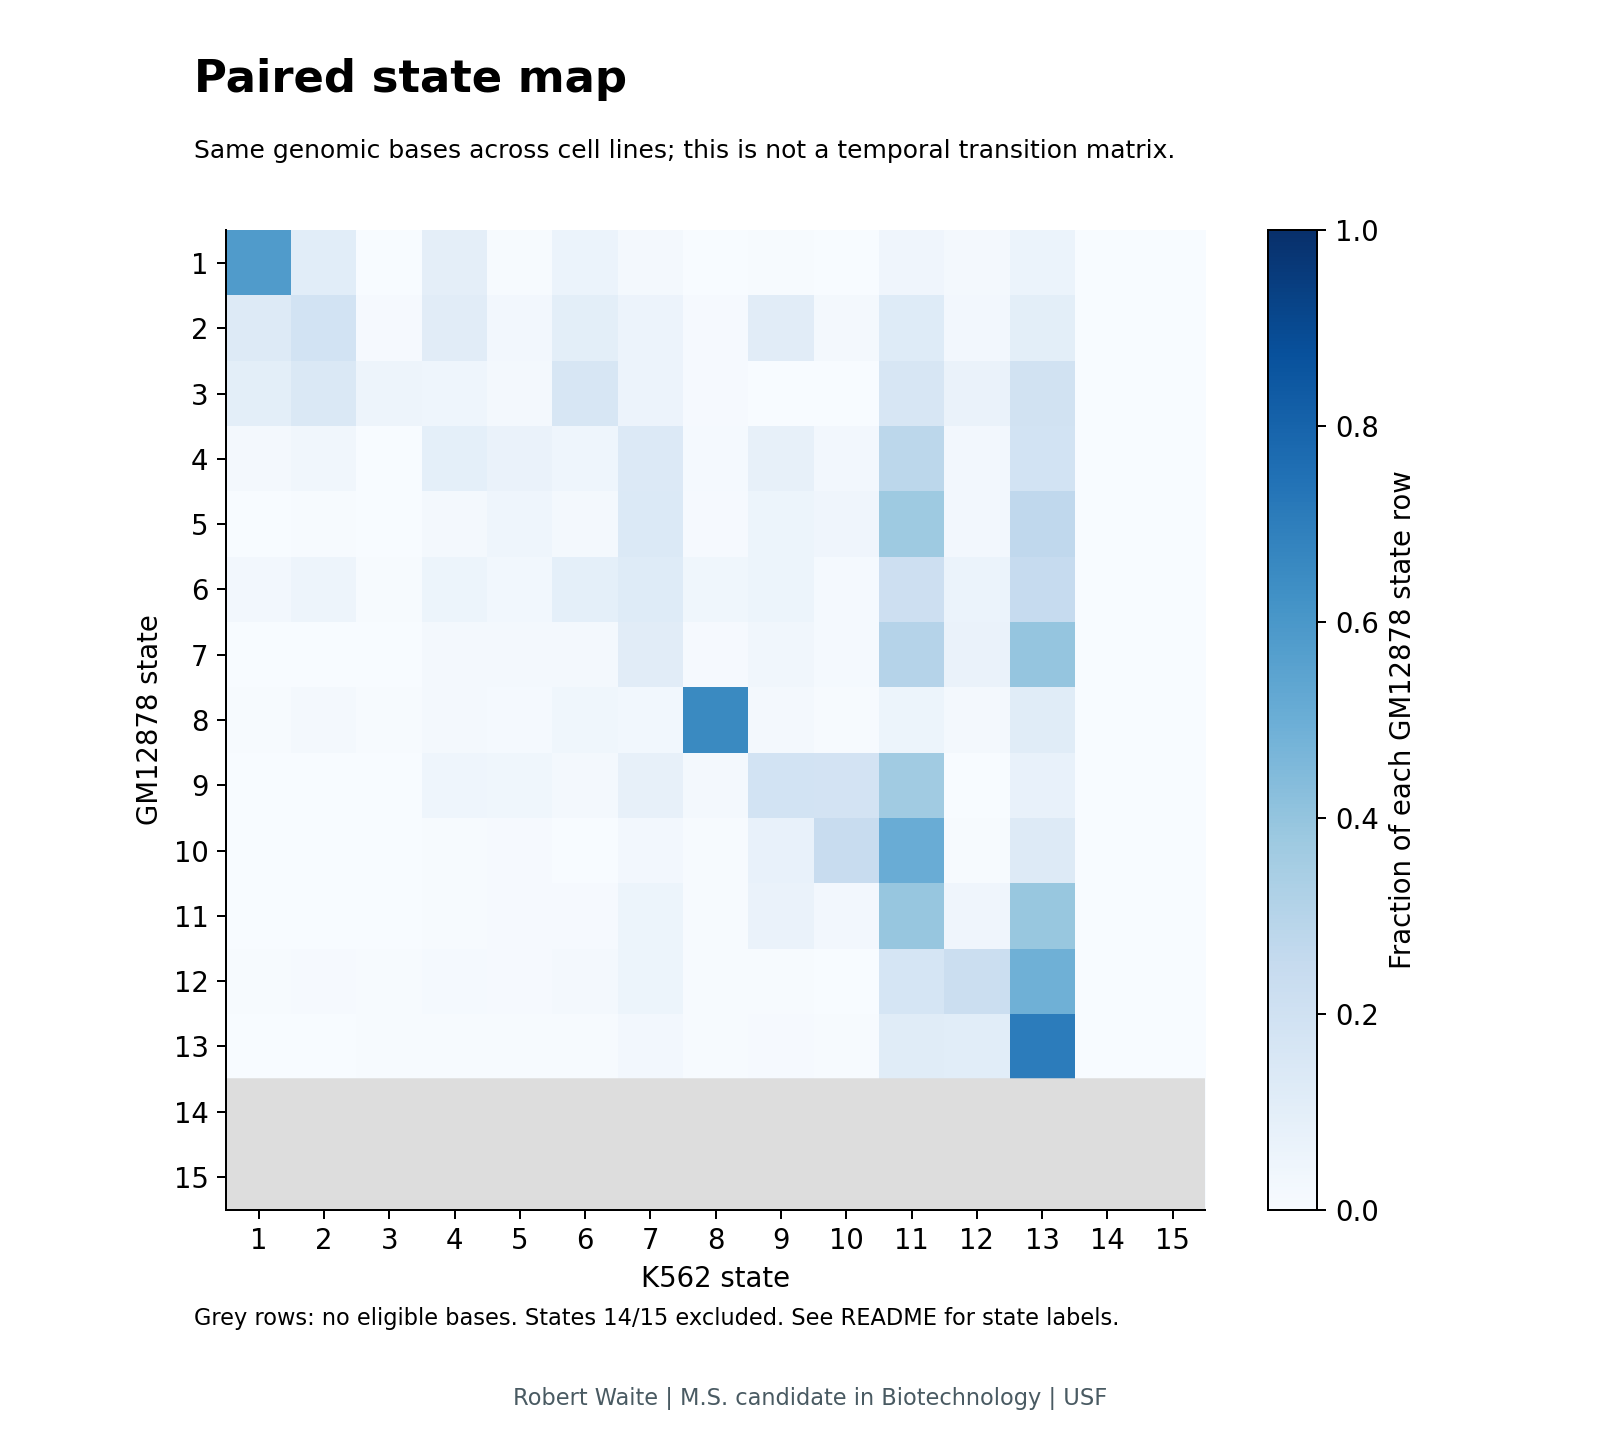

Identical state assignments: 50.95% of primary eligible territory


In [7]:
display(Image(filename=str(ROOT / "figures/03_paired_states.png")))
print(f"Identical state assignments: {primary['same_state_fraction']:.2%} of primary eligible territory")


## Interpretation (secondary analysis)

Across 31,467,632 common eligible bases of hg19 chromosome 22, active-promoter
annotations share 265,800 of 560,800 union bases (Jaccard 0.474), whereas
strong-enhancer annotations share 123,400 of 1,685,802 union bases (0.073).
Thus the enhancer class is less shared in this two-line comparison. The
40.08-percentage-point gap remains positive when repetitive/CNV territory is
retained and when the enhancer class includes weak/poised states.

A biological interpretation is that candidate enhancer usage is more dependent
on cellular context than active-promoter annotation in these lines. This is
consistent with the established chromatin-state framework, rather than evidence
of a new mechanism. A competing explanation is that differences in histone
signals, sample quality, transformation or model assignments contribute to the
observed discordance. GM12878 and K562 differ in lineage and disease context;
they do not provide a controlled differentiation experiment.

The analysis is confined to one chromosome, one annotation release, hard state
assignments and a pair of cell lines. It cannot establish enhancer activity,
target genes, temporal switching or remodeling rates. Bases are correlated, and
there are no independent biological replicates for inferential testing. A
proposed next experiment would compare selected shared and line-specific
candidate enhancers in matched functional assays in both contexts. No such
experiment was performed here.

## Reproducibility

`data/processed/` contains exact intervals, QC, coverage, overlaps, paired-state
counts and an environment record. `docs/index.html` is the offline explorer.
`tests/` checks interval mathematics against independent reference calculations.
The continuous-integration workflow reruns the analysis and checks deterministic
data products. This is secondary analysis of the cited investigators' source
measurements and published ChromHMM assignments.

## References

- [Ernst et al. (2011), Nature](https://doi.org/10.1038/nature09906)
- [ENCODE Project Consortium (2012), Nature](https://doi.org/10.1038/nature11247)
- [UCSC state labels and liftOver provenance](https://genome.ucsc.edu/cgi-bin/hgTrackUi?db=hg19&g=wgEncodeBroadHmm)
- [ENCODE data-use terms](https://genome.ucsc.edu/ENCODE/terms.html)
- GM12878: wgEncodeEH000784 / GSM936082; K562: wgEncodeEH000790 / GSM936088.
